# Day 39: DAS Reconstruction Using Linear Interpolation

## Objective
Reconstruct photoacoustic images using full sensor data,
incomplete sensor data, and linearly interpolated sensor signals.

## Methods
- Full-array DAS reference
- DAS with inactive sensors
- DAS after linear interpolation

Full signal matrix shape: (32, 600)
Number of inactive sensors: 8
Missing sensor indices (0-based): [1, 5, 9, 13, 17, 21, 25, 29]
Interpolated signal matrix shape: (32, 600)
DAS reconstruction completed.
Image shape: (100, 100)

Image errors relative to full-array DAS reference:
Incomplete sensor data: {'MAE': 1.87869445319226, 'RMSE': 2.672719028774945, 'Max absolute error': 7.991632098505814}
Linear interpolation: {'MAE': 0.02309349721662082, 'RMSE': 0.03424056163235236, 'Max absolute error': 0.13848989583368265}
RMSE reduction after interpolation (%): 98.71888659961213


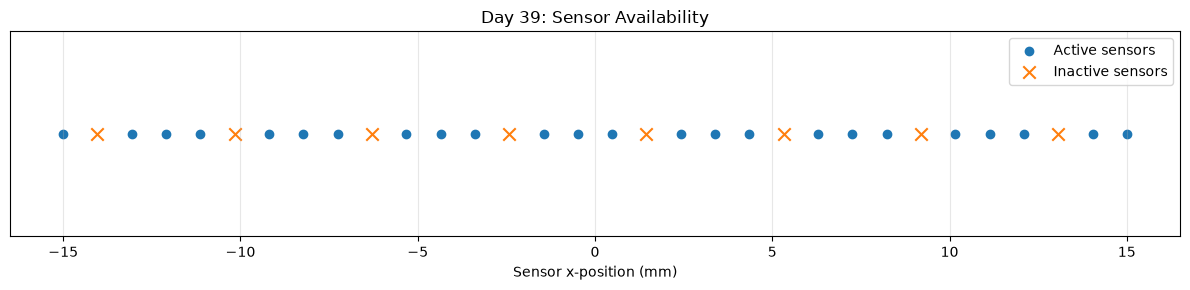

C:\Users\user\AppData\Local\Temp\ipykernel_2624\176225798.py:241: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


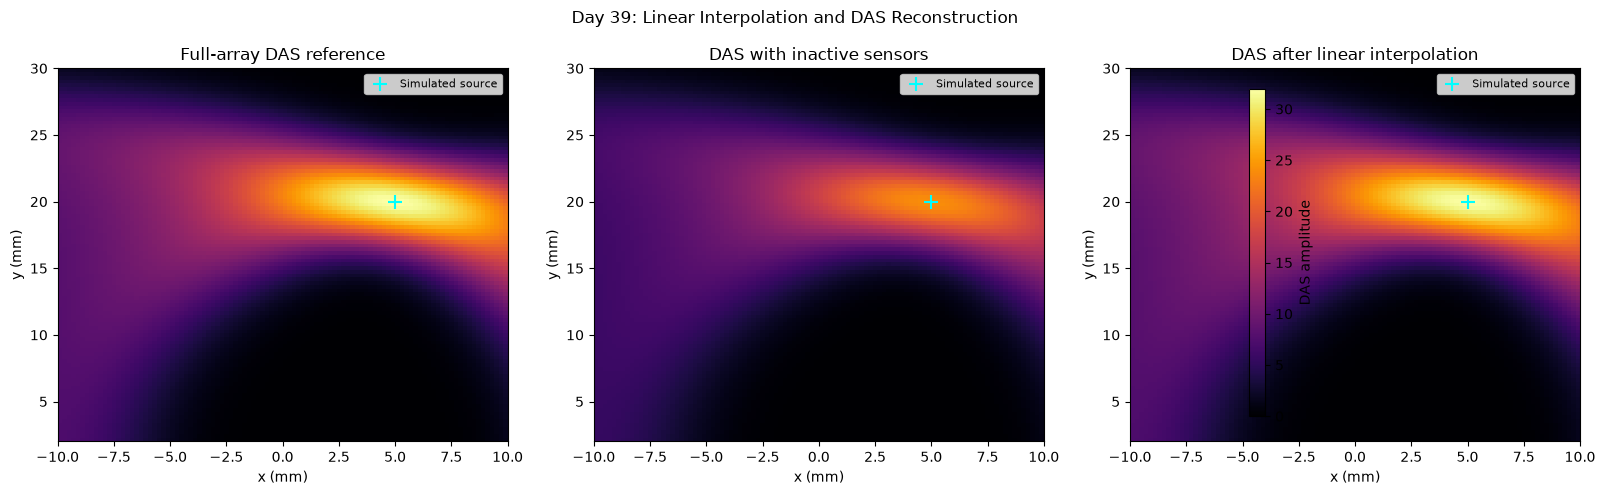

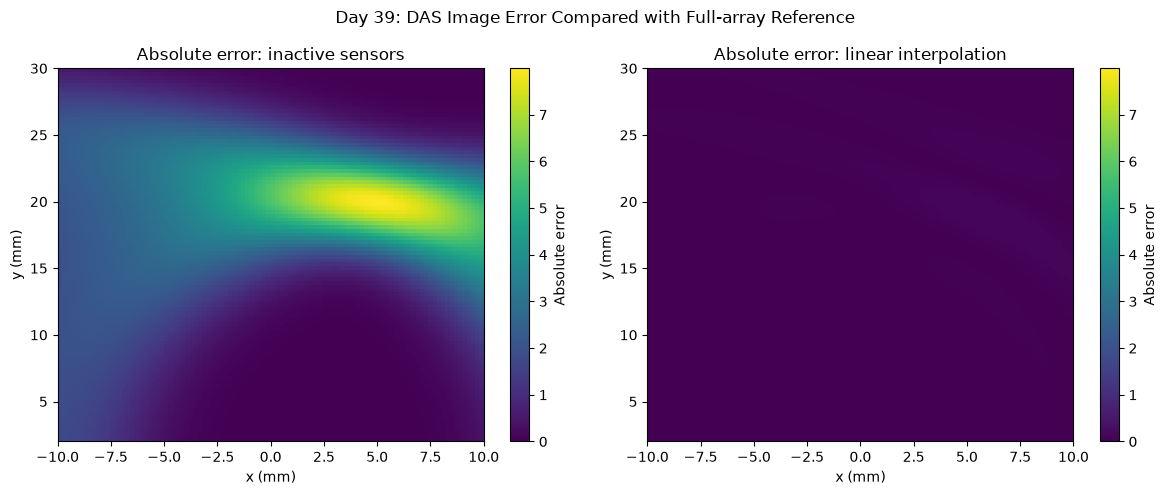


Results saved to: ..\outputs\day39_das_linear_results.json
{
    "day": 39,
    "method": "DAS with linear interpolation",
    "num_sensors": 32,
    "num_inactive_sensors": 8,
    "dropout_fraction": 0.25,
    "inactive_sensor_indices_zero_based": [
        1,
        5,
        9,
        13,
        17,
        21,
        25,
        29
    ],
    "reference": "Full-array DAS image (synthetic reference, not physical ground truth)",
    "missing_sensor_image_errors": {
        "MAE": 1.87869445319226,
        "RMSE": 2.672719028774945,
        "Max absolute error": 7.991632098505814
    },
    "linear_interpolation_image_errors": {
        "MAE": 0.02309349721662082,
        "RMSE": 0.03424056163235236,
        "Max absolute error": 0.13848989583368265
    },
    "rmse_reduction_percent": 98.71888659961213,
    "outputs": [
        "day39_sensor_mask.png",
        "day39_das_linear_comparison.png",
        "day39_das_absolute_error.png"
    ]
}


In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------
num_sensors = 32
num_samples = 600
fs = 10e6
c = 1500.0  # Speed of sound (m/s)

source_x = 5e-3
source_y = 20e-3
pulse_width = 1.5e-6

# Sensor array along y = 0
sensor_x = np.linspace(-15e-3, 15e-3, num_sensors)
sensor_y = np.zeros(num_sensors)

time = np.arange(num_samples) / fs

# Image reconstruction grid
x_grid = np.linspace(-10e-3, 10e-3, 100)
y_grid = np.linspace(2e-3, 30e-3, 100)
X, Y = np.meshgrid(x_grid, y_grid)

# Output directory: project_root/outputs
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 2. Generate synthetic sensor signals
# --------------------------------------------------
signals_full = np.zeros((num_sensors, num_samples))

for i in range(num_sensors):
    distance = np.sqrt(
        (sensor_x[i] - source_x) ** 2
        + (sensor_y[i] - source_y) ** 2
    )

    arrival_time = distance / c

    signals_full[i] = np.exp(
        -0.5 * ((time - arrival_time) / pulse_width) ** 2
    )

print("Full signal matrix shape:", signals_full.shape)

# --------------------------------------------------
# 3. Simulate inactive sensors
# --------------------------------------------------
missing_indices = np.array([1, 5, 9, 13, 17, 21, 25, 29])

sensor_mask = np.ones(num_sensors, dtype=bool)
sensor_mask[missing_indices] = False

signals_missing = signals_full.copy()
signals_missing[~sensor_mask, :] = 0.0

print("Number of inactive sensors:", len(missing_indices))
print("Missing sensor indices (0-based):", missing_indices.tolist())

# --------------------------------------------------
# 4. Linear interpolation across sensor positions
# --------------------------------------------------
known_x = sensor_x[sensor_mask]
known_signals = signals_full[sensor_mask, :]

linear_interpolator = interp1d(
    known_x,
    known_signals,
    axis=0,
    kind="linear",
    bounds_error=False,
    fill_value="extrapolate"
)

signals_linear = signals_missing.copy()
signals_linear[~sensor_mask, :] = linear_interpolator(
    sensor_x[~sensor_mask]
)

print("Interpolated signal matrix shape:", signals_linear.shape)

# --------------------------------------------------
# 5. Delay-and-Sum reconstruction
# --------------------------------------------------
def das_reconstruction(signals):
    """
    Reconstruct a DAS image by sampling each sensor signal
    at the estimated source-to-sensor travel time for every pixel.
    """
    image = np.zeros_like(X, dtype=float)

    for i in range(num_sensors):
        distance_map = np.sqrt(
            (X - sensor_x[i]) ** 2
            + (Y - sensor_y[i]) ** 2
        )

        travel_time_map = distance_map / c

        delayed_values = np.interp(
            travel_time_map.ravel(),
            time,
            signals[i],
            left=0.0,
            right=0.0
        ).reshape(X.shape)

        image += delayed_values

    return image


# Reconstruct the three images
image_full = das_reconstruction(signals_full)
image_missing = das_reconstruction(signals_missing)
image_linear = das_reconstruction(signals_linear)

print("DAS reconstruction completed.")
print("Image shape:", image_full.shape)

# --------------------------------------------------
# 6. Calculate image comparison metrics
# --------------------------------------------------
def calculate_errors(reference, estimate):
    difference = estimate - reference

    return {
        "MAE": float(np.mean(np.abs(difference))),
        "RMSE": float(np.sqrt(np.mean(difference ** 2))),
        "Max absolute error": float(np.max(np.abs(difference)))
    }


missing_errors = calculate_errors(image_full, image_missing)
linear_errors = calculate_errors(image_full, image_linear)

print("\nImage errors relative to full-array DAS reference:")
print("Incomplete sensor data:", missing_errors)
print("Linear interpolation:", linear_errors)

if missing_errors["RMSE"] > 0:
    rmse_reduction = (
        (missing_errors["RMSE"] - linear_errors["RMSE"])
        / missing_errors["RMSE"]
        * 100
    )
else:
    rmse_reduction = None

print("RMSE reduction after interpolation (%):", rmse_reduction)

# --------------------------------------------------
# 7. Plot sensor mask
# --------------------------------------------------
plt.figure(figsize=(12, 3))

plt.scatter(
    sensor_x[sensor_mask] * 1e3,
    np.zeros(sensor_mask.sum()),
    label="Active sensors",
    marker="o"
)

plt.scatter(
    sensor_x[~sensor_mask] * 1e3,
    np.zeros((~sensor_mask).sum()),
    label="Inactive sensors",
    marker="x",
    s=80
)

plt.xlabel("Sensor x-position (mm)")
plt.yticks([])
plt.title("Day 39: Sensor Availability")
plt.legend()
plt.grid(True, axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    output_dir / "day39_sensor_mask.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# --------------------------------------------------
# 8. Plot image reconstruction comparison
# --------------------------------------------------
extent = [
    x_grid[0] * 1e3,
    x_grid[-1] * 1e3,
    y_grid[0] * 1e3,
    y_grid[-1] * 1e3
]

vmax = max(float(np.max(image_full)), 1e-12)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

image_titles = [
    "Full-array DAS reference",
    "DAS with inactive sensors",
    "DAS after linear interpolation"
]

images = [image_full, image_missing, image_linear]

for ax, img, title in zip(axes, images, image_titles):
    im = ax.imshow(
        img,
        extent=extent,
        origin="lower",
        aspect="auto",
        cmap="inferno",
        vmin=0,
        vmax=vmax
    )
    ax.scatter(
        [source_x * 1e3],
        [source_y * 1e3],
        marker="+",
        color="cyan",
        s=90,
        label="Simulated source"
    )
    ax.set_title(title)
    ax.set_xlabel("x (mm)")
    ax.set_ylabel("y (mm)")
    ax.legend(loc="upper right", fontsize=8)

fig.colorbar(im, ax=axes, label="DAS amplitude", shrink=0.85)
fig.suptitle("Day 39: Linear Interpolation and DAS Reconstruction")
plt.tight_layout()

plt.savefig(
    output_dir / "day39_das_linear_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# --------------------------------------------------
# 9. Plot absolute error maps
# --------------------------------------------------
error_missing = np.abs(image_missing - image_full)
error_linear = np.abs(image_linear - image_full)

error_max = max(
    float(np.max(error_missing)),
    float(np.max(error_linear)),
    1e-12
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

im0 = axes[0].imshow(
    error_missing,
    extent=extent,
    origin="lower",
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=error_max
)
axes[0].set_title("Absolute error: inactive sensors")
axes[0].set_xlabel("x (mm)")
axes[0].set_ylabel("y (mm)")
fig.colorbar(im0, ax=axes[0], label="Absolute error")

im1 = axes[1].imshow(
    error_linear,
    extent=extent,
    origin="lower",
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=error_max
)
axes[1].set_title("Absolute error: linear interpolation")
axes[1].set_xlabel("x (mm)")
axes[1].set_ylabel("y (mm)")
fig.colorbar(im1, ax=axes[1], label="Absolute error")

fig.suptitle("Day 39: DAS Image Error Compared with Full-array Reference")
plt.tight_layout()

plt.savefig(
    output_dir / "day39_das_absolute_error.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# --------------------------------------------------
# 10. Save numerical results to JSON
# --------------------------------------------------
results = {
    "day": 39,
    "method": "DAS with linear interpolation",
    "num_sensors": int(num_sensors),
    "num_inactive_sensors": int(len(missing_indices)),
    "dropout_fraction": float(len(missing_indices) / num_sensors),
    "inactive_sensor_indices_zero_based": missing_indices.tolist(),
    "reference": "Full-array DAS image (synthetic reference, not physical ground truth)",
    "missing_sensor_image_errors": missing_errors,
    "linear_interpolation_image_errors": linear_errors,
    "rmse_reduction_percent": (
        float(rmse_reduction) if rmse_reduction is not None else None
    ),
    "outputs": [
        "day39_sensor_mask.png",
        "day39_das_linear_comparison.png",
        "day39_das_absolute_error.png"
    ]
}

results_path = output_dir / "day39_das_linear_results.json"

with open(results_path, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=4, ensure_ascii=False)

print("\nResults saved to:", results_path)
print(json.dumps(results, indent=4, ensure_ascii=False))